## STEP 0: Generation of Matrix

In [6]:
import numpy as np

# Visualization setings
np.set_printoptions(precision=6, suppress=True)

def gerar_matrizes(matricula) :
    """
    Gera as matrizes dos Problemas 1 e 2 a partir de uma matrícula com 6 digitos .
    """
    digitos = [int(d) for d in str(matricula)]

    if len(digitos) != 6:
        raise ValueError("A matrícula deve possuir exatamente 6 digitos.")

    d1, d2, d3, d4, d5, d6 = digitos

    # Problema 1
    A1 = np.array([
    [17 + d1, d2, 34 + d3, 24 + d4],
    [7 + d5, 15 + d6, 3 + d1, 9 + d2],
    [2, 0, d3, 31],
    [0, 0, 0, 31 + d4]
    ], dtype=float)

    # Problema 2
    A2 = np . array ([
    [-5 - d1, -1, 0, 2, 1],
    [-7, -1 - d2, 9, 7, 2],
    [4, 3, 8 + d3, -2, -2],
    [-7, 3, 4, -6 - d4, -2],
    [0, -2, -7, -7, -9 - d5]
    ], dtype=float)

    return A1, A2

matricula = 318375
A1, A2 = gerar_matrizes(matricula)

print("\nMatriz do Problema 1: ")
print(A1)
print("\nMatriz do Problema 2: ")
print(A2)


Matriz do Problema 1: 
[[20.  1. 42. 27.]
 [14. 20.  6. 10.]
 [ 2.  0.  8. 31.]
 [ 0.  0.  0. 34.]]

Matriz do Problema 2: 
[[ -8.  -1.   0.   2.   1.]
 [ -7.  -2.   9.   7.   2.]
 [  4.   3.  16.  -2.  -2.]
 [ -7.   3.   4.  -9.  -2.]
 [  0.  -2.  -7.  -7. -16.]]


Na matriz $A_1$, o elemento $a_{31} = 2 \neq 0$, assim a matriz não está na forma de Hessenberg superior (elementos abaixo da subdiagonal iguais a zero), com isso, temos um impedimento de uso direto do algoritmo QR sobre esta matriz porque:

1. A fatoração QR via Householder ou Gram-Schmidt modificado custa $O(n^3)$ operações de ponto flutuante. Como a convergência global para a matriz de Schur exige $O(n)$ iterações, o esforço computacional total escalaria para $O(n^4)$.
    
    1.1 Se $A$ for previamente reduzida a uma matriz de Hessenberg superior $H$, a estrutura esparsa abaixo da subdiagonal permite que a fatoração $H=QR$ aniquile apenas um único elemento por coluna, substituindo o uso pesado de Householder por uma sequência de $n - 1$ rotações de Givens planas, levando o custo computacional de $O(n^3)$ para $O(n^2)$. Assim, o custo global de convergência cai para $O(n^3)$.

2. A matriz de Hessenberg é invariante sob a iteração QR: se $H_{k} = Q_{k}R_{k}$ é a fatoração de uma matriz de Hessenberg superior, a próxima matriz na sequência de similaridade, $H_{k+1} = Q_{k+1}R_{k+1}$, também é garantidamente de Hesseberg superior. O algoritmo QR revela os autovalores conduzindo os elementos subdiagonais a zero. Quando um elemento subdiagonal atinge uma magnitude tolerável próxima ao épsilon da aritmética de máquina,  $\epsilon_{mach}$, a matriz experimenta o fenômeno de "deflação" ou "desacoplamento espectral", particionando-se em blocos: $H = \begin{bmatrix} H_{11} & H_{12} \\ 0 & H_{22} \end{bmatrix}$. Isso quebra o problema original de dimensão $n$ em subproblemas independentes e menores, permitindo que as iterações subsequentes foquem apenas no bloco ativo.

Além disso, na linha 4 de $A_1$ o elemento $a_{43} = 0$ já está desacoplado, o que implica que $\lambda = 34$ já é um autovalor visível por inspeção, e o algoritmo de Hessenberg + QR preservará essa estrutura.

## STEP 1: The Hessenberg Reduction

No problema 1a nosso objetivo é obter a Decomposição Real de Schur: $A = QTQ^T \iff Q^TAQ = T$, onde $Q \in \mathbb{R}^{n \times n}$ é ortogonal ($Q^TQ = I$) e $T \in \mathbb{R}^{n \times n}$ é quase triangular superior (triangular superior em blocos $1 \times 1$ para autovalores reais e blocos $2 \times 2$ para pares de autovalores complexos conjugados).
Assim, precisamos primeiramente contruir uma matriz ortogonal $U = P_1P_2 \dots P_{n-2}$ (produto de reflexões de Householder), tal que:

$$H = U^TAU$$

seja Hessenberg superior. Com isso, aplicando as rotações de Givens sobre $H$ e acumulando-as na própria matriz ortogonal, obteremos a matriz $Q$ final da decomposição de Schur.

### 1.1. Reflexão de Householder

Dado um vetor coluna $x \in \mathbb{R}^m$, queremos encontrar um vetor $v \in \mathbb{R}^m$ e uma constante $c = \frac{2}{v^Tv}$ tais que a matriz de reflexão de Householder:

$$P = I - cvv^T$$

reflita $x$ sobre o primeiro eixo canônico $e_1 = [1, 0, \dots, 0]^T$, zerando todas as componentes de $x$ abaixo da primeira:

$$Px = (I - cvv^T)x = \alpha e_1, \text{onde } \alpha = \pm \|x\|_2$$

Para construir $v$ de forma numericamente estável, evitando cancelamento catastrófico na subtração de números de mesmo sinal:

1. Calculamos a norma euclidiana $\|x\|_2 = \sqrt{\sum_{i=1}^m x_i^2}$ com a função `calc_norm_2()`:

In [7]:
# Calculation of norm-2
def calc_norm_2(x: np.ndarray) -> float:
    """Calculates the euclidian norm-2 of a vector: sqrt(x^T x)."""
    return float(np.sqrt(np.sum(x ** 2)))

2. Escolhemos o sinal de $\alpha$ oposto ao sinal da primeira componente $x_1$:
$$\alpha = -\operatorname{sign}(x_1)\|x\|_2 \quad (\text{usando }\operatorname{sign}(x_1) = 1 \text{ se } x_1 \ge 0 \text{ e } -1 \text{ se } x_1 < 0)$$

3. Definimos o vetor de Householder:
$$v = x - \alpha e_1 \implies \begin{cases} v_1 = x_1 - \alpha = x_1 + \operatorname{sign}(x_1)\|x\|_2 \\ v_i = x_i, \quad \text{para } i = 2, \dots, m \end{cases}$$

4. Calculamos $c = \frac{2}{v^Tv}$ (com a proteção de que, se $vTv = 0$, então $c = 0$).

A função `house()` implementa os passos 2, 3 e 4 descritos anteriormente:

In [8]:
# Calculation of Householder Reflexition
def house(x: np.ndarray):
    """
    Calculates the vextor v of Householder and the scalar c = 2 / (v^T v)
    such that P*x = (I - c * v * v^T)*x = alpha * e_1
    """
    # Ensuring that x is treated as a 1D vector to facilitate manipulation
    x_vec = x.flatten().astype(float).copy()
    x_norm = calc_norm_2(x_vec)

    # If all the entries below x[0] are already zero, we don't need to reflect.
    if calc_norm_2(x_vec[1:]) == 0:
        v = np.zeros_like(x_vec).reshape(-1, 1)     # Copy vector x with entries equal to 0, and transform v into a column vector (m x 1)
        c = 0.0
        return v, c
    
    # Item 2: Choose the opposite alpha sign to x[0] to avoid catastrophic cancellation.
    sign = 1.0 if x_vec[0] >= 0.0 else -1.0
    alpha = -sign * x_norm

    # Item 3: v = x - alpha * e_1
    v = x_vec.copy()
    v[0] = v[0] - alpha
    v = v.reshape(-1, 1)        # Transform v into a column vector (m x 1)

    # Item 4: c = 2 / (v^T v)
    vTv = float((v.T @ v)[0, 0])        # [0, 0] extracts the pure scalar
    c = 2.0 / vTv if vTv > 0.0 else 0.0

    return v, c

### 1.2 Hessenberg Reduction
A função `hessenberg_reduction()` implementa o algoritmo de redução de Hessenberg, recebendo uma matriz $A \in \mathbb{R}^{n \times n}$ e tendo como saída a matriz ortogonal $U$ e a matriz de Hessinberg superior $H$, tais que $H = U^TAU$. Nesta função, no passo $j$ começamos na linha $j + 1$ into até $n$: $x = H(j + 1:n, j)$. Assim:

* Multiplicar à esquerda por $P_j^T$ combina apenas as linhas $j + 1$ até $n$, zerando as entradas $j + 2$ até $n$ da coluna $j$ abaixo da subdiagonal.
* Multiplicar à direita por $P_j$ combina apenas as colunas $j + 1$ até $n$, não alterando a coluna $j$ e preservando os zeros recém-criados.

Se usássemos uma reflexão $P_1$ para zerar as entradas 2 até $n$ da primeira coluna, como fazemos na fatoração QR tradicional, ao multiplicarmos à direita na transformação de similaridade $P_1^TAP_1$, a multiplicação por $P_1$ combinaria a primeira coluna com as demais e destruiria todos os zeros já criados.

In [9]:
def hessenberg_reduction(A: np.ndarray):
    """Hessenberg Reduction algorithm."""
    n = A.shape[0]
    U = np.eye(n, dtype=float)
    H = A.astype(float).copy()

    for j in range(n - 2):
        # v = house(H(j+1:n, j)), c = 2 / (v^T v)
        x_sub = H[j + 1 : n, j]
        v, c = house(x_sub)

        if c != 0.0:
            # H(j+1:n, j:n) = H(j+1:n, j:n) - c * v * (v^T * H(j+1:n, j:n))
            H[j + 1 : n, j:n] = H[j + 1 : n, j:n] - c * (
                v @ (v.T @ H[j + 1 : n, j:n])
            )

            # H(1:n, j+1:n) = H(1:n, j+1:n) - c * (H(1:n, j+1:n) * v) * v^T
            H[:, j + 1 : n] = H[:, j + 1 : n] - c * ((H[:, j + 1 : n] @ v) @ v.T)

            # U(1:n, j+1:n) = U(1:n, j+1:n) - c * (U(1:n, j+1:n) * v) * v^T
            U[:, j + 1 : n] = U[:, j + 1 : n] - c * ((U[:, j + 1 : n] @ v) @ v.T)

    return U, H

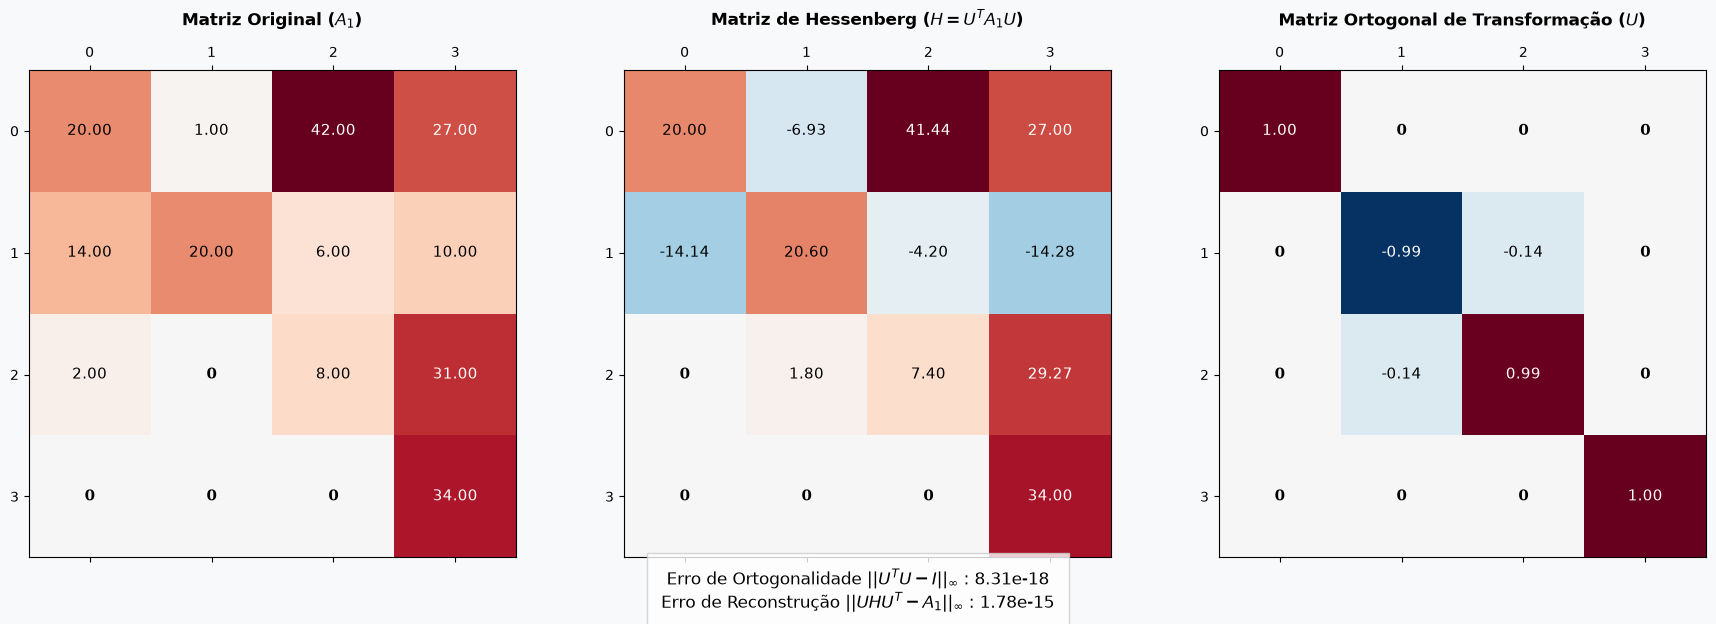

In [11]:
import matplotlib.pyplot as plt
# ==============================================================================
# ETAPA 2: RENDERIZAÇÃO GRÁFICA DA TOPOLOGIA MATRICIAL
# ==============================================================================
def renderizar_matriz(ax, matriz, titulo, threshold_zero=1e-10):
    """
    Renderiza uma matriz como mapa de calor, destacando os zeros estruturais.
    Valores abaixo do threshold_zero são considerados aniquilados numericamente.
    """
    max_val = np.max(np.abs(matriz))
    # Colormap divergente para destacar amplitudes positivas e negativas
    cax = ax.matshow(matriz, cmap='RdBu_r', vmin=-max_val, vmax=max_val)
    
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            valor = matriz[i, j]
            
            # Se o valor for numericamente zero, aplica formatação limpa e em negrito
            if abs(valor) < threshold_zero:
                texto = "0"
                cor_texto = "black"
                peso = "bold"
            else:
                texto = f"{valor:.2f}"
                # Ajusta a cor do texto para contraste com o fundo escuro do colormap
                cor_texto = "white" if abs(valor) > (max_val * 0.5) else "black"
                peso = "normal"
                
            ax.text(j, i, texto, va='center', ha='center', color=cor_texto, weight=peso, fontsize=11)
            
    ax.set_title(titulo, pad=15, fontsize=12, fontweight='bold')
    ax.set_xticks(range(matriz.shape[1]))
    ax.set_yticks(range(matriz.shape[0]))
    return cax

def visualizar_reducao(A, H, U):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('#f8f9fa')
    
    # 1. Plot da Matriz Original
    renderizar_matriz(axes[0], A, "Matriz Original ($A_1$)")
    
    # 2. Plot da Matriz de Hessenberg
    renderizar_matriz(axes[1], H, "Matriz de Hessenberg ($H = U^T A_1 U$)")
    
    # 3. Plot da Matriz Ortogonal
    renderizar_matriz(axes[2], U, "Matriz Ortogonal de Transformação ($U$)")
    
    # Verificações de Sanidade (Norma do Supremo)
    erro_ortogonalidade = np.max(np.abs(U.T @ U - np.eye(A.shape[0])))
    erro_similaridade = np.max(np.abs(U @ H @ U.T - A))
    
    texto_metricas = (
        f"Erro de Ortogonalidade $||U^T U - I||_{{\\infty}}$ : {erro_ortogonalidade:.2e}\n"
        f"Erro de Reconstrução $||U H U^T - A_1||_{{\\infty}}$ : {erro_similaridade:.2e}"
    )
    
    plt.figtext(0.5, 0.02, texto_metricas, ha="center", fontsize=12, 
                bbox={"facecolor":"white", "alpha":0.8, "pad":10, "edgecolor":"#cccccc"})
    
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plt.show()

if __name__ == "__main__":
    matricula = "318375"
    A1, A2 = gerar_matrizes(matricula)
    U, H = hessenberg_reduction(A1)
    
    visualizar_reducao(A1, H, U)